# Exploratory Data Analysis — Predict Future Sales

**Objetivo:** entender el comportamiento de las ventas diarias de 1C Company, una de las mayores cadenas
rusas de software, videojuegos y entretenimiento, para preparar el *forecasting* de las ventas mensuales
por par tienda-producto de **noviembre de 2015**.

## Configuración inicial

### Librerías

Importación de librerías agrupadas por categoría y definición del estilo global de las gráficas.

In [1]:
# Manipulación de datos
from pathlib import Path

import numpy as np
import pandas as pd

# Gráficas
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Notebooks
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("styler.format.precision", 2)

### Parámetros y carga de datos

Rutas parametrizadas de los archivos de entrada e intermedios, y funciones de carga que validan que cada
archivo exista.

In [2]:
DATA_PATH = Path("../data/raw")
INTERIM_PATH = Path("../data/interim")
CLEAN_SALES_FILE = "sales_train_clean.parquet"
ENRICHED_SALES_FILE = "sales_enriched.parquet"

FILES = {
    "sales_train": "sales_train.csv",
    "items": "items.csv",
    "item_categories": "item_categories.csv",
    "shops": "shops.csv",
    "test": "test.csv",
}


def load_csv(file_name: str, data_path: Path = DATA_PATH) -> pd.DataFrame:
    """Carga un CSV desde data_path; lanza FileNotFoundError si no existe."""
    file_path = Path(data_path) / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")
    return pd.read_csv(file_path)


def load_parquet(file_name: str, data_path: Path = INTERIM_PATH) -> pd.DataFrame:
    """Carga un Parquet intermedio desde data_path; lanza FileNotFoundError si no existe."""
    file_path = Path(data_path) / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")
    return pd.read_parquet(file_path)

### Presentación de tablas

Función común para mostrar tablas sin índice, con las columnas de texto alineadas a la izquierda y separador
de miles en las cifras (excepto en los identificadores).

In [3]:
def is_id_column(column: str) -> bool:
    return column in ("ID", "Índice", "date_block_num") or column.endswith("_id")


def style_table(df: pd.DataFrame, formats: dict | None = None):
    """Devuelve un Styler sin índice, con las columnas de texto (y sus encabezados) a la izquierda."""
    text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
    id_cols = [c for c in df.columns if is_id_column(c)]
    other_cols = [c for c in df.columns if c not in id_cols]
    styler = df.style.hide(axis="index").format(thousands=",", subset=other_cols, na_rep="—")
    if id_cols:
        styler = styler.format("{}", subset=id_cols, na_rep="—")
    if formats:
        styler = styler.format(formats, subset=list(formats), na_rep="—")
    if text_cols:
        styler = styler.set_properties(subset=text_cols, **{"text-align": "left"})
        styler = styler.set_table_styles(
            [
                {"selector": f"th.col_heading.col{df.columns.get_loc(c)}",
                 "props": [("text-align", "left")]}
                for c in text_cols
            ],
            overwrite=False,
        )
    return styler

## 2. Comprensión inicial del dataset

### 2.a Carga de los archivos y vista preliminar

Se cargan los cinco archivos del dataset y se muestran sus primeras filas para reconocer su estructura.

In [4]:
datasets = {name: load_csv(file_name) for name, file_name in FILES.items()}

sales_train = datasets["sales_train"]
items = datasets["items"]
item_categories = datasets["item_categories"]
shops = datasets["shops"]
test = datasets["test"]

for name, df in datasets.items():
    print(f"{name}.csv")
    display(style_table(df.head()))

sales_train.csv


date,date_block_num,shop_id,item_id,item_price,item_cnt_day
02.01.2013,0,59,22154,999.00,1.00
03.01.2013,0,25,2552,899.00,1.00
05.01.2013,0,25,2552,899.00,-1.00
06.01.2013,0,25,2554,"1,709.05",1.00
15.01.2013,0,25,2555,"1,099.00",1.00


items.csv


item_name,item_id,item_category_id
! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
"!ABBYY FineReader 12 Professional Edition Full [PC, Цифровая версия]",1,76
***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
***КОРОБКА (СТЕКЛО) D,4,40


item_categories.csv


item_category_name,item_category_id
PC - Гарнитуры/Наушники,0
Аксессуары - PS2,1
Аксессуары - PS3,2
Аксессуары - PS4,3
Аксессуары - PSP,4


shops.csv


shop_name,shop_id
"!Якутск Орджоникидзе, 56 фран",0
"!Якутск ТЦ ""Центральный"" фран",1
"Адыгея ТЦ ""Мега""",2
"Балашиха ТРК ""Октябрь-Киномир""",3
"Волжский ТЦ ""Волга Молл""",4


test.csv


ID,shop_id,item_id
0,5,5037
1,5,5320
2,5,5233
3,5,5232
4,5,5268


**Interpretación**

- `sales_train` es la tabla de hechos: cada fila es la venta de un producto (`item_id`) en una tienda
  (`shop_id`) en un día (`date`), con su precio y unidades vendidas. `date_block_num` indexa el mes.
- `items`, `item_categories` y `shops` son catálogos que traducen los identificadores a nombres. Los nombres
  están en ruso, por lo que el análisis se apoya en los identificadores.
- `items` enlaza cada producto con su categoría mediante `item_category_id`, lo que permite llevar la
  categoría a las ventas.
- `test` no tiene fecha ni ventas: solo `ID`, `shop_id` e `item_id`. Son los pares tienda-producto cuyas
  ventas de noviembre de 2015 hay que pronosticar.

### 2.b Resumen de dimensiones y memoria

Número de filas, columnas y uso de memoria (en MB, incluyendo el contenido de las columnas de texto) de cada
archivo.

In [5]:
summary = pd.DataFrame(
    [
        {
            "Archivo": FILES[name],
            "Filas": df.shape[0],
            "Columnas": df.shape[1],
            "Memoria (MB)": df.memory_usage(deep=True).sum() / 1024**2,
        }
        for name, df in datasets.items()
    ]
)

style_table(summary, {"Memoria (MB)": "{:,.2f}"})

Archivo,Filas,Columnas,Memoria (MB)
sales_train.csv,"2,935,849",6,162.39
items.csv,"22,170",3,1.79
item_categories.csv,84,2,0.00
shops.csv,60,2,0.00
test.csv,"214,200",3,4.90


**Interpretación**

- `sales_train.csv` concentra casi todo el volumen: 2,935,849 registros diarios y 162.39 MB en memoria, frente
  a menos de 5 MB de cada uno de los demás archivos.
- Los catálogos son pequeños: 22,170 productos, 84 categorías y 60 tiendas.
- `test.csv` tiene 214,200 pares tienda-producto a pronosticar.
- El dataset cabe en memoria sin problema, aunque conviene optimizar tipos de `sales_train` antes de agregar
  o cruzar tablas (sección 3.a).

### 2.c Diccionario de variables

Descripción de cada variable, el archivo en el que aparece y su tipo.

In [6]:
data_dictionary = pd.DataFrame(
    [
        ("date", "sales_train", "fecha", "Fecha de la venta, en formato dd.mm.yyyy."),
        ("date_block_num", "sales_train", "fecha",
         "Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."),
        ("shop_id", "sales_train, shops, test", "identificador", "Identificador único de la tienda."),
        ("item_id", "sales_train, items, test", "identificador", "Identificador único del producto."),
        ("item_price", "sales_train", "numérica", "Precio unitario del producto en la venta (rublos)."),
        ("item_cnt_day", "sales_train", "numérica",
         "Unidades vendidas en el día; los valores negativos corresponden a devoluciones."),
        ("item_name", "items", "categórica", "Nombre del producto."),
        ("item_category_id", "items, item_categories", "identificador",
         "Identificador único de la categoría del producto."),
        ("item_category_name", "item_categories", "categórica", "Nombre de la categoría del producto."),
        ("shop_name", "shops", "categórica", "Nombre de la tienda."),
    ],
    columns=["Columna", "Archivo", "Tipo", "Descripción"],
)

style_table(data_dictionary)

Columna,Archivo,Tipo,Descripción
date,sales_train,fecha,"Fecha de la venta, en formato dd.mm.yyyy."
date_block_num,sales_train,fecha,"Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."
shop_id,"sales_train, shops, test",identificador,Identificador único de la tienda.
item_id,"sales_train, items, test",identificador,Identificador único del producto.
item_price,sales_train,numérica,Precio unitario del producto en la venta (rublos).
item_cnt_day,sales_train,numérica,Unidades vendidas en el día; los valores negativos corresponden a devoluciones.
item_name,items,categórica,Nombre del producto.
item_category_id,"items, item_categories",identificador,Identificador único de la categoría del producto.
item_category_name,item_categories,categórica,Nombre de la categoría del producto.
shop_name,shops,categórica,Nombre de la tienda.


**Variable objetivo**

La competencia no pide predecir ventas diarias, sino **`item_cnt_month`**: el total de unidades vendidas de
cada producto en cada tienda durante un mes. Se obtiene agregando `item_cnt_day` por `date_block_num`,
`shop_id` e `item_id`:

$$\text{item\_cnt\_month}_{m,\,s,\,i} = \sum_{d \in m} \text{item\_cnt\_day}_{d,\,s,\,i}$$

El pronóstico corresponde al mes siguiente al último del histórico (noviembre de 2015, `date_block_num` = 34)
para cada par tienda-producto de `test.csv`.

### 2.d Rango temporal

Se interpreta `date` con el formato dd.mm.yyyy para calcular el periodo que cubre el histórico de ventas. La
conversión definitiva de la columna se hace en la sección 3.b.

In [7]:
dates = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")
date_min, date_max = dates.min(), dates.max()

time_range = pd.DataFrame(
    {
        "Métrica": [
            "Fecha mínima",
            "Fecha máxima",
            "Días del periodo",
            "Días con registros",
            "Meses cubiertos (date_block_num)",
        ],
        "Valor": [
            date_min.strftime("%d/%m/%Y"),
            date_max.strftime("%d/%m/%Y"),
            f"{(date_max - date_min).days + 1:,}",
            f"{dates.nunique():,}",
            f"{sales_train['date_block_num'].nunique()} "
            f"({sales_train['date_block_num'].min()} a {sales_train['date_block_num'].max()})",
        ],
    }
)

style_table(time_range)

Métrica,Valor
Fecha mínima,01/01/2013
Fecha máxima,31/10/2015
Días del periodo,"1,034"
Días con registros,"1,034"
Meses cubiertos (date_block_num),34 (0 a 33)


**Interpretación**

- El histórico va del 01/01/2013 al 31/10/2015: 1,034 días, y todos tienen al menos un registro, así que
  no hay huecos en la serie diaria.
- Esos días se agrupan en 34 meses (`date_block_num` de 0 a 33). Noviembre de 2015, el mes a pronosticar,
  corresponde a `date_block_num` = 34.
- El histórico incluye dos meses de noviembre completos (2013 y 2014), que sirven de referencia para la
  estacionalidad del mes a predecir.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos

Se compara el tipo con el que pandas leyó cada columna con el tipo esperado según el diccionario de la
sección 2.c. Se considera que coinciden cuando el tipo de pandas es compatible con el esperado: fecha →
`datetime64`, identificador → entero, numérica → entero o decimal y categórica → texto. `date_block_num` es
un índice entero de mes, por lo que se espera como entero.

In [8]:
EXPECTED_TYPES = {
    "date": "fecha",
    "date_block_num": "fecha",
    "shop_id": "identificador",
    "item_id": "identificador",
    "item_price": "numérica",
    "item_cnt_day": "numérica",
    "item_name": "categórica",
    "item_category_id": "identificador",
    "item_category_name": "categórica",
    "shop_name": "categórica",
    "ID": "identificador",
}


def dtype_matches(column: str, series: pd.Series) -> bool:
    expected = EXPECTED_TYPES[column]
    if column == "date_block_num":
        return pd.api.types.is_integer_dtype(series)
    return {
        "fecha": pd.api.types.is_datetime64_any_dtype,
        "identificador": pd.api.types.is_integer_dtype,
        "numérica": pd.api.types.is_numeric_dtype,
        "categórica": pd.api.types.is_string_dtype,
    }[expected](series)


def dtype_report(datasets: dict) -> pd.DataFrame:
    rows = [
        {
            "Archivo": FILES[name],
            "Columna": col,
            "Tipo en pandas": str(df[col].dtype),
            "Tipo esperado": EXPECTED_TYPES[col],
            "Coincide": "Sí" if dtype_matches(col, df[col]) else "No",
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
    return pd.DataFrame(rows)


style_table(dtype_report(datasets))

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int64,fecha,Sí
sales_train.csv,shop_id,int64,identificador,Sí
sales_train.csv,item_id,int64,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,float64,numérica,Sí
items.csv,item_name,str,categórica,Sí
items.csv,item_id,int64,identificador,Sí
items.csv,item_category_id,int64,identificador,Sí
item_categories.csv,item_category_name,str,categórica,Sí


**Interpretación**

- Todas las columnas coinciden con su tipo esperado salvo `date`, que pandas lee como texto (`str`) en lugar
  de fecha. Se corrige en la sección 3.b.
- Los identificadores y las cantidades se leen como `int64` y `float64`, que ocupan 8 bytes por valor aunque
  sus rangos son pequeños. Hay margen para reducir memoria.

#### Optimización de tipos numéricos

Se convierte cada identificador y columna numérica al entero más pequeño que admite su rango, comprobando
antes que todos los valores caben en el tipo de destino. Se conservan dos excepciones deliberadas:

- `item_cnt_day` pasa a `int32` y no a `int16`: pandas conserva el tipo al sumar con `groupby`, y una
  suma mensual de unidades desbordaría `int16` (máximo 32,767).
- `item_price` se mantiene en `float64` para no perder precisión en los precios con decimales al calcular
  ingresos.

In [9]:
TARGET_DTYPES = {
    "sales_train": {"date_block_num": "int8", "shop_id": "int8", "item_id": "int16",
                    "item_cnt_day": "int32"},
    "items": {"item_id": "int16", "item_category_id": "int8"},
    "item_categories": {"item_category_id": "int8"},
    "shops": {"shop_id": "int8"},
    "test": {"ID": "int32", "shop_id": "int8", "item_id": "int16"},
}


def safe_cast(series: pd.Series, dtype: str) -> pd.Series:
    """Convierte a un entero más pequeño verificando que no haya decimales ni desbordamiento."""
    info = np.iinfo(dtype)
    if not (series % 1 == 0).all():
        raise ValueError(f"{series.name} tiene valores no enteros")
    if series.min() < info.min or series.max() > info.max:
        raise ValueError(f"{series.name} no cabe en {dtype}")
    return series.astype(dtype)


def memory_mb(df: pd.DataFrame) -> float:
    return df.memory_usage(deep=True).sum() / 1024**2


memory_before = memory_mb(sales_train)

for name, dtypes in TARGET_DTYPES.items():
    df = datasets[name]
    for col, dtype in dtypes.items():
        df[col] = safe_cast(df[col], dtype)

memory_after = memory_mb(sales_train)

memory_table = pd.DataFrame(
    {
        "Etapa": ["Antes (tipos de lectura)", "Después (tipos optimizados)"],
        "Memoria (MB)": [memory_before, memory_after],
        "Reducción (%)": [0.0, (1 - memory_after / memory_before) * 100],
    }
)

display(style_table(dtype_report({"sales_train": sales_train})))
style_table(memory_table, {"Memoria (MB)": "{:,.2f}", "Reducción (%)": "{:.1f}"})

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int8,fecha,Sí
sales_train.csv,shop_id,int8,identificador,Sí
sales_train.csv,item_id,int16,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,int32,numérica,Sí


Etapa,Memoria (MB),Reducción (%)
Antes (tipos de lectura),162.39,0.0
Después (tipos optimizados),95.19,41.4


**Interpretación**

- La conversión se completó sin errores: todos los valores de `item_cnt_day` son enteros y todos los
  identificadores caben en `int8` o `int16`.
- `sales_train` pasa de 162.39 MB a 95.19 MB (−41.4 %). La columna `date` sigue almacenada como texto; su
  conversión a fecha en 3.b reduce la memoria todavía más.

### 3.b Formato de fecha

Se verifica que `date` llega como texto con formato dd.mm.yyyy, se convierte a `datetime64` con
`format="%d.%m.%Y"` y se comprueba que la conversión no generó valores nulos (`NaT`).

In [10]:
dtype_before = str(sales_train["date"].dtype)
sample_values = ", ".join(sales_train["date"].head(3))
valid_format = sales_train["date"].str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum()

sales_train["date"] = pd.to_datetime(sales_train["date"], format="%d.%m.%Y", errors="coerce")

date_check = pd.DataFrame(
    {
        "Verificación": [
            "Tipo antes de la conversión",
            "Valores de ejemplo",
            "Registros con formato dd.mm.yyyy",
            "Tipo después de la conversión",
            "Valores NaT tras la conversión",
            "Memoria de sales_train (MB)",
        ],
        "Resultado": [
            dtype_before,
            sample_values,
            f"{valid_format:,} de {len(sales_train):,}",
            str(sales_train["date"].dtype),
            f"{sales_train['date'].isna().sum():,}",
            f"{memory_mb(sales_train):,.2f}",
        ],
    }
)

style_table(date_check)

Verificación,Resultado
Tipo antes de la conversión,str
Valores de ejemplo,"02.01.2013, 03.01.2013, 05.01.2013"
Registros con formato dd.mm.yyyy,"2,935,849 de 2,935,849"
Tipo después de la conversión,datetime64[us]
Valores NaT tras la conversión,0
Memoria de sales_train (MB),67.20


**Interpretación**

- Los 2,935,849 registros de `date` siguen el patrón dd.mm.yyyy, de modo que el formato es homogéneo.
- Tras la conversión, `date` es `datetime64` y no hay ningún `NaT`: todas las fechas eran válidas.
- Con la fecha convertida, `sales_train` ocupa 67.20 MB, un 58.6 % menos que los 162.39 MB iniciales.

### 3.c Frecuencia temporal

#### Días sin ventas y días por mes

Se compara el calendario completo entre la primera y la última fecha con los días que tienen registros, y se
cuenta cuántos días con ventas tiene cada `date_block_num` frente a los días del mes calendario.

In [11]:
full_calendar = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
missing_days = full_calendar.difference(sales_train["date"].unique())
print(f"Días del calendario: {len(full_calendar):,} | Días sin registros: {len(missing_days):,}")

days_per_block = (
    sales_train.groupby("date_block_num")
    .agg(month_start=("date", "min"), days_with_sales=("date", "nunique"))
    .reset_index()
)
days_per_block["Mes"] = days_per_block["month_start"].dt.strftime("%Y-%m")
days_per_block["Días del mes"] = days_per_block["month_start"].dt.days_in_month
days_per_block["Completo"] = np.where(
    days_per_block["days_with_sales"] == days_per_block["Días del mes"], "Sí", "No"
)
days_per_block = days_per_block.rename(columns={"days_with_sales": "Días con ventas"})[
    ["date_block_num", "Mes", "Días con ventas", "Días del mes", "Completo"]
]

style_table(days_per_block)

Días del calendario: 1,034 | Días sin registros: 0


date_block_num,Mes,Días con ventas,Días del mes,Completo
0,2013-01,31,31,Sí
1,2013-02,28,28,Sí
2,2013-03,31,31,Sí
3,2013-04,30,30,Sí
4,2013-05,31,31,Sí
5,2013-06,30,30,Sí
6,2013-07,31,31,Sí
7,2013-08,31,31,Sí
8,2013-09,30,30,Sí
9,2013-10,31,31,Sí


**Interpretación**

- Los 1,034 días del calendario tienen registros: no falta ningún día.
- Los 34 bloques tienen tantos días con ventas como días tiene su mes calendario (20 meses de 31 días,
  11 de 30 y 3 febreros de 28), así que todos los meses están completos y son comparables entre sí.

#### Consistencia de `date_block_num`

Se calcula el bloque esperado a partir de la fecha, como (año − 2013) × 12 + (mes − 1), y se compara con
`date_block_num`.

In [12]:
expected_block = (sales_train["date"].dt.year - 2013) * 12 + (sales_train["date"].dt.month - 1)
mismatches = int((expected_block != sales_train["date_block_num"]).sum())

block_check = pd.DataFrame(
    {
        "Métrica": ["Registros evaluados", "Registros que no coinciden"],
        "Valor": [len(sales_train), mismatches],
    }
)

style_table(block_check)

Métrica,Valor
Registros evaluados,"2,935,849"
Registros que no coinciden,0


**Interpretación**

- Ninguno de los 2,935,849 registros presenta discrepancia: `date_block_num` corresponde exactamente al mes
  de `date`. Ambas columnas son coherentes y `date_block_num` puede usarse con seguridad como índice mensual.

#### Transacciones por día

Número de registros diarios de `sales_train` (cada registro es un par tienda-producto con ventas en el
día), con su media móvil de 30 días para separar la tendencia del ruido diario.

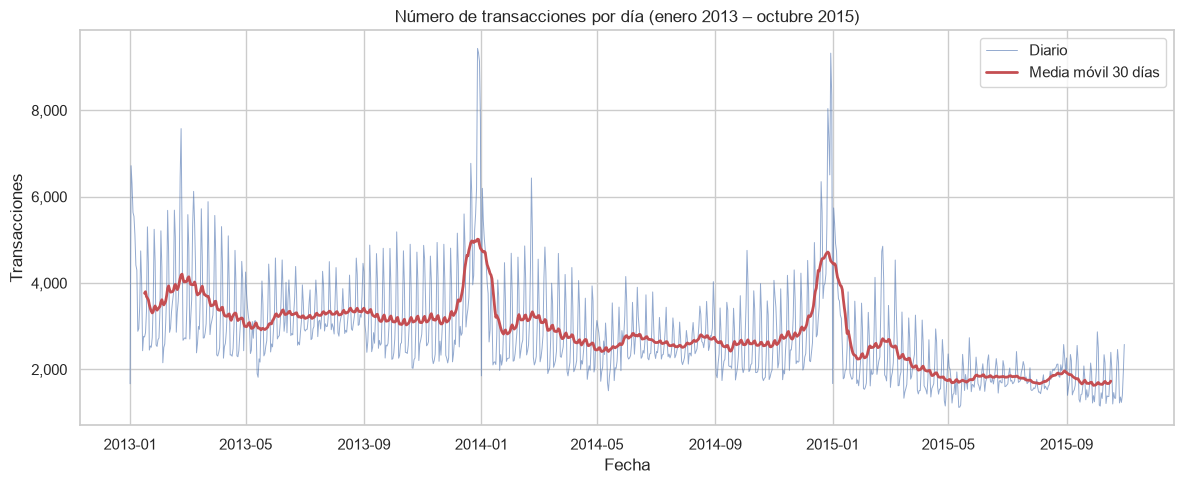

Métrica,Valor
Media diaria,"2,839"
Desviación estándar,"1,166"
Coeficiente de variación,41.1%
Mínimo,"1,123 (12/05/2015)"
Máximo,"9,434 (28/12/2013)"
Media diaria 2013,"3,473"
Media diaria 2014,"2,893"
Media diaria 2015,"2,015"
Día de la semana con más transacciones (media),"Sábado (3,989)"
Día de la semana con menos transacciones (media),"Lunes (2,293)"


In [13]:
daily_transactions = sales_train.groupby("date").size()
rolling_30 = daily_transactions.rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_transactions.index, daily_transactions, linewidth=0.7, alpha=0.6, label="Diario")
ax.plot(rolling_30.index, rolling_30, linewidth=2, color="C3", label="Media móvil 30 días")
ax.set_title("Número de transacciones por día (enero 2013 – octubre 2015)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Transacciones")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

DAY_NAMES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
by_weekday = daily_transactions.groupby(daily_transactions.index.day_of_week).mean()
by_year = daily_transactions.groupby(daily_transactions.index.year).mean()

daily_summary = pd.DataFrame(
    {
        "Métrica": [
            "Media diaria",
            "Desviación estándar",
            "Coeficiente de variación",
            "Mínimo",
            "Máximo",
            *[f"Media diaria {year}" for year in by_year.index],
            "Día de la semana con más transacciones (media)",
            "Día de la semana con menos transacciones (media)",
        ],
        "Valor": [
            f"{daily_transactions.mean():,.0f}",
            f"{daily_transactions.std():,.0f}",
            f"{daily_transactions.std() / daily_transactions.mean():.1%}",
            f"{daily_transactions.min():,} ({daily_transactions.idxmin():%d/%m/%Y})",
            f"{daily_transactions.max():,} ({daily_transactions.idxmax():%d/%m/%Y})",
            *[f"{value:,.0f}" for value in by_year],
            f"{DAY_NAMES[by_weekday.idxmax()]} ({by_weekday.max():,.0f})",
            f"{DAY_NAMES[by_weekday.idxmin()]} ({by_weekday.min():,.0f})",
        ],
    }
)

style_table(daily_summary)

**Interpretación**

- La serie diaria es muy ruidosa: la media es de 2,839 transacciones por día con una desviación de 1,166
  (coeficiente de variación del 41.1 %), y va de 1,123 (12/05/2015) a 9,434 (28/12/2013).
- Hay un ciclo semanal marcado: el sábado promedia 3,989 transacciones frente a 2,293 del lunes. Es la
  oscilación de alta frecuencia que se ve en la línea diaria.
- Los picos más altos se concentran a finales de diciembre de cada año, lo que indica una fuerte
  estacionalidad anual por las compras de fin de año.
- La media móvil muestra una tendencia descendente: la media diaria baja de 3,473 en 2013 a 2,893 en 2014
  y a 2,015 en 2015.

#### Conclusión: frecuencia de agregación

Conviene trabajar con **frecuencia mensual** (`date_block_num`):

- **El objetivo es mensual.** `item_cnt_month` y `test.csv` se definen por mes y par tienda-producto, así
  que el modelo debe aprender y predecir a esa escala.
- **Reduce el ruido.** La serie diaria tiene un coeficiente de variación del 41.1 % y un ciclo semanal
  marcado. Al sumar por mes, ese ruido y el efecto del día de la semana se compensan.
- **Los meses son comparables.** Los 34 bloques están completos y `date_block_num` coincide con la fecha en
  todos los registros, así que la agregación mensual no introduce sesgos por días faltantes.
- **Conserva la señal útil.** La tendencia descendente y la estacionalidad de diciembre siguen siendo
  visibles a nivel mensual.

La frecuencia semanal no aporta ventajas: las semanas no encajan con los meses, que es la unidad del
pronóstico, y la serie seguiría siendo más ruidosa. La información diaria puede aprovecharse después como
variables derivadas (por ejemplo, número de días con ventas en el mes), pero el conjunto de modelado debe
construirse a nivel mensual.

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos

Número y porcentaje de valores nulos por columna en los cinco archivos.

In [14]:
null_report = pd.DataFrame(
    [
        {
            "Archivo": FILES[name],
            "Columna": col,
            "Nulos": int(df[col].isna().sum()),
            "% de nulos": df[col].isna().mean() * 100,
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
)

style_table(null_report, {"% de nulos": "{:.2f}"})

Archivo,Columna,Nulos,% de nulos
sales_train.csv,date,0,0.00
sales_train.csv,date_block_num,0,0.00
sales_train.csv,shop_id,0,0.00
sales_train.csv,item_id,0,0.00
sales_train.csv,item_price,0,0.00
sales_train.csv,item_cnt_day,0,0.00
items.csv,item_name,0,0.00
items.csv,item_id,0,0.00
items.csv,item_category_id,0,0.00
item_categories.csv,item_category_name,0,0.00


**Interpretación**

- Ninguna de las 16 columnas de los cinco archivos tiene valores nulos, así que no se requiere imputación
  por ausencia de datos.
- Los problemas de calidad del dataset no son de valores faltantes, sino de valores inválidos y duplicados,
  que se analizan a continuación.

### 4.b Estrategia de tratamiento y valores inválidos

#### Precios menores o iguales a cero

Se identifican las ventas con `item_price` ≤ 0 y se calcula su precio de reemplazo: la mediana de los precios
válidos del mismo producto en la misma tienda y mes; si no existe, la del producto en el mes; y si tampoco
existe, el registro se elimina.

In [15]:
def impute_invalid_prices(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Imputa item_price <= 0 con la mediana de referencia; elimina los registros sin referencia."""
    df = df.copy()
    valid = df[df["item_price"] > 0]
    median_shop_month = valid.groupby(["item_id", "shop_id", "date_block_num"])["item_price"].median()
    median_month = valid.groupby(["item_id", "date_block_num"])["item_price"].median()

    log = []
    for idx, row in df[df["item_price"] <= 0].iterrows():
        key_shop = (row["item_id"], row["shop_id"], row["date_block_num"])
        key_month = (row["item_id"], row["date_block_num"])
        if key_shop in median_shop_month.index:
            new_price, reference = median_shop_month[key_shop], "producto-tienda-mes"
        elif key_month in median_month.index:
            new_price, reference = median_month[key_month], "producto-mes"
        else:
            new_price, reference = np.nan, "sin referencia (se elimina)"
        df.loc[idx, "item_price"] = new_price
        log.append({"Índice": idx, "date": row["date"].strftime("%d/%m/%Y"), "shop_id": row["shop_id"],
                    "item_id": row["item_id"], "date_block_num": row["date_block_num"],
                    "Precio original": row["item_price"], "Precio imputado": new_price,
                    "Referencia": reference})

    return df.dropna(subset=["item_price"]), pd.DataFrame(log)


invalid_prices = sales_train[sales_train["item_price"] <= 0]
print(f"Registros con item_price <= 0: {len(invalid_prices):,}")

_, price_log = impute_invalid_prices(sales_train)
display(style_table(price_log))

first_invalid = invalid_prices.iloc[0]
reference_sales = sales_train[
    (sales_train["item_id"] == first_invalid["item_id"])
    & (sales_train["shop_id"] == first_invalid["shop_id"])
    & (sales_train["date_block_num"] == first_invalid["date_block_num"])
].assign(date=lambda d: d["date"].dt.strftime("%d/%m/%Y"))
print("Ventas del mismo producto, tienda y mes:")
style_table(reference_sales)

Registros con item_price <= 0: 1


Índice,date,shop_id,item_id,date_block_num,Precio original,Precio imputado,Referencia
484683,15/05/2013,32,2973,4,-1.00,"1,874.00",producto-tienda-mes


Ventas del mismo producto, tienda y mes:


date,date_block_num,shop_id,item_id,item_price,item_cnt_day
23/05/2013,4,32,2973,"1,249.00",1
15/05/2013,4,32,2973,-1.00,1
06/05/2013,4,32,2973,"2,499.00",1


**Interpretación**

- Solo hay 1 registro con precio inválido: el producto 2973 en la tienda 32 el 15/05/2013, con
  `item_price` = −1 y una unidad vendida.
- En ese mismo mes y tienda el producto tiene otras dos ventas válidas, a 1,249.00 y 2,499.00, por lo que se
  imputa la mediana: 1,874.00.
- **Decisión:** imputar en lugar de eliminar. El −1 es un código de error en el precio, pero la cantidad
  vendida es válida, y eliminar la fila restaría una unidad a la variable objetivo. Con referencia en la
  misma tienda y mes, la mediana es un reemplazo realista y resistente a precios extremos.

#### Cantidades negativas (devoluciones)

Se cuantifican los registros con `item_cnt_day` < 0, su peso sobre los registros y las unidades, y las
categorías en las que se concentran.

In [16]:
returns = sales_train[sales_train["item_cnt_day"] < 0]
units_sold = sales_train.loc[sales_train["item_cnt_day"] > 0, "item_cnt_day"].sum()
units_returned = -returns["item_cnt_day"].sum()

returns_summary = pd.DataFrame(
    {
        "Métrica": [
            "Registros con devolución",
            "% de los registros",
            "Unidades devueltas",
            "% de las unidades vendidas",
            "Unidades netas (vendidas − devueltas)",
        ],
        "Valor": [
            f"{len(returns):,}",
            f"{len(returns) / len(sales_train):.2%}",
            f"{units_returned:,}",
            f"{units_returned / units_sold:.2%}",
            f"{units_sold - units_returned:,}",
        ],
    }
)
display(style_table(returns_summary))

sales_with_category = sales_train.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
returns_by_category = (
    sales_with_category.assign(is_return=sales_with_category["item_cnt_day"] < 0)
    .groupby("item_category_id")
    .agg(records=("is_return", "size"), return_records=("is_return", "sum"))
    .reset_index()
    .merge(item_categories, on="item_category_id")
    .sort_values("return_records", ascending=False)
)
returns_by_category["% de las devoluciones"] = (
    returns_by_category["return_records"] / returns_by_category["return_records"].sum() * 100
)
returns_by_category["% acumulado"] = returns_by_category["% de las devoluciones"].cumsum()
returns_by_category["Tasa de devolución (%)"] = (
    returns_by_category["return_records"] / returns_by_category["records"] * 100
)
top_return_categories = returns_by_category.head(10).rename(
    columns={"item_category_name": "Categoría", "return_records": "Devoluciones",
             "records": "Registros de la categoría"}
)[["item_category_id", "Categoría", "Devoluciones", "% de las devoluciones", "% acumulado",
   "Registros de la categoría", "Tasa de devolución (%)"]]

print(f"Categorías con al menos una devolución: {(returns_by_category['return_records'] > 0).sum()} "
      f"de {len(item_categories)}")
style_table(
    top_return_categories,
    {"% de las devoluciones": "{:.1f}", "% acumulado": "{:.1f}", "Tasa de devolución (%)": "{:.2f}"},
)

Métrica,Valor
Registros con devolución,"7,356"
% de los registros,0.25%
Unidades devueltas,"7,541"
% de las unidades vendidas,0.21%
Unidades netas (vendidas − devueltas),"3,648,206"


Categorías con al menos una devolución: 60 de 84


item_category_id,Categoría,Devoluciones,% de las devoluciones,% acumulado,Registros de la categoría,Tasa de devolución (%)
19,Игры - PS3,847,11.5,11.5,"208,219",0.41
30,Игры PC - Стандартные издания,804,10.9,22.4,"351,591",0.23
37,Кино - Blu-Ray,742,10.1,32.5,"192,674",0.39
40,Кино - DVD,714,9.7,42.2,"564,652",0.13
23,Игры - XBOX 360,622,8.5,50.7,"146,789",0.42
55,Музыка - CD локального производства,458,6.2,56.9,"339,585",0.13
20,Игры - PS4,421,5.7,62.6,"79,058",0.53
28,Игры PC - Дополнительные издания,268,3.6,66.3,"121,539",0.22
38,Кино - Blu-Ray 3D,223,3.0,69.3,"42,718",0.52
21,Игры - PSP,189,2.6,71.9,"32,164",0.59


**Interpretación**

- Hay 7,356 registros con devolución (0.25 % de los registros), que suman 7,541 unidades devueltas: el
  0.21 % de las unidades vendidas. Las ventas netas son 3,648,206 unidades.
- Las devoluciones aparecen en 60 de las 84 categorías, pero se concentran: las 10 primeras reúnen el
  71.9 %. Dominan los videojuegos (PS3, PC, XBOX 360, PS4, PSP: 42.8 % entre las seis categorías de juegos
  del top 10) y el cine en formato físico (Blu-Ray, DVD y Blu-Ray 3D: 22.8 %).
- La tasa de devolución por categoría es baja en todas (entre 0.13 % y 0.59 % de sus registros); las más
  altas corresponden a consolas de nicho o recientes, como PSP (0.59 %) y PS4 (0.53 %).
- **Decisión:** conservar las devoluciones como ventas netas. `item_cnt_month` se define como la suma de
  `item_cnt_day`, incluidas las devoluciones, así que eliminarlas sobrestimaría el objetivo. Su peso es
  además pequeño (0.21 % de las unidades).

#### Resumen de la estrategia de tratamiento

Decisiones adoptadas para los problemas de valores faltantes e inválidos.

In [17]:
strategy = pd.DataFrame(
    [
        ("Valores nulos", int(null_report["Nulos"].sum()), "Sin tratamiento",
         "Ninguna columna de los cinco archivos tiene nulos."),
        ("item_price ≤ 0", len(invalid_prices), "Imputar con la mediana de referencia",
         "La venta es válida y solo falla el precio; hay referencia del mismo producto, tienda y mes."),
        ("item_cnt_day < 0 (devoluciones)", len(returns), "Conservar como ventas netas",
         "El objetivo item_cnt_month es la suma neta de item_cnt_day; eliminarlas lo sobrestimaría."),
    ],
    columns=["Problema", "Registros afectados", "Decisión", "Justificación"],
)

style_table(strategy)

Problema,Registros afectados,Decisión,Justificación
Valores nulos,0,Sin tratamiento,Ninguna columna de los cinco archivos tiene nulos.
item_price ≤ 0,1,Imputar con la mediana de referencia,"La venta es válida y solo falla el precio; hay referencia del mismo producto, tienda y mes."
item_cnt_day < 0 (devoluciones),"7,356",Conservar como ventas netas,El objetivo item_cnt_month es la suma neta de item_cnt_day; eliminarlas lo sobrestimaría.


### 4.c Duplicados

#### Registros duplicados exactos en `sales_train`

Se buscan filas idénticas en todas sus columnas (fecha, mes, tienda, producto, precio y cantidad).

In [18]:
exact_duplicates = sales_train[sales_train.duplicated(keep=False)].sort_values(
    ["date", "shop_id", "item_id"]
)
print(f"Filas sobrantes por duplicado exacto: {sales_train.duplicated().sum():,} "
      f"({len(exact_duplicates):,} filas implicadas)")

style_table(exact_duplicates.reset_index(names="Índice").assign(
    date=lambda d: d["date"].dt.strftime("%d/%m/%Y")
))

Filas sobrantes por duplicado exacto: 6 (12 filas implicadas)


Índice,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,05/01/2013,0,54,20130,149.00,1
76962,05/01/2013,0,54,20130,149.00,1
1435365,23/02/2014,13,50,3423,999.00,1
1435367,23/02/2014,13,50,3423,999.00,1
1496765,23/03/2014,14,21,3423,999.00,1
1496766,23/03/2014,14,21,3423,999.00,1
1671872,01/05/2014,16,50,3423,999.00,1
1671873,01/05/2014,16,50,3423,999.00,1
1866322,12/07/2014,18,25,3423,999.00,1
1866340,12/07/2014,18,25,3423,999.00,1


**Interpretación**

- Hay 6 filas duplicadas exactas (12 filas implicadas, en pares). Todas son ventas de una unidad, y 4 de los
  6 pares corresponden al mismo producto (3423) a 999.00 en distintas tiendas y fechas.
- **Decisión:** eliminar los duplicados y conservar la primera aparición. `sales_train` registra las ventas
  diarias agregadas por tienda, producto y precio, así que dos filas idénticas apuntan a un error de carga
  y no a dos ventas distintas. El impacto es mínimo: 6 unidades sobre más de 3.6 millones.

#### Tiendas duplicadas en `shops.csv`

Se normalizan los nombres de las tiendas quitando los marcadores "!", "?", "²" y "фран" (franquicia) para
detectar IDs distintos con el mismo nombre. Para cada par se revisan los meses con ventas y su presencia en
`test.csv`.

In [19]:
def month_ranges(blocks) -> str:
    """Convierte una lista de date_block_num en rangos compactos, p. ej. '0-24, 26-33'."""
    blocks = sorted(set(int(b) for b in blocks))
    groups = [[blocks[0]]]
    for block in blocks[1:]:
        if block == groups[-1][-1] + 1:
            groups[-1].append(block)
        else:
            groups.append([block])
    return ", ".join(f"{g[0]}-{g[-1]}" if len(g) > 1 else f"{g[0]}" for g in groups)


shops_norm = shops.assign(
    normalized_name=shops["shop_name"]
    .str.replace(r"[!?²]", "", regex=True)
    .str.replace("фран", "")
    .str.strip()
    .str.lower()
)
duplicate_groups = shops_norm.groupby("normalized_name")["shop_id"].apply(list)
duplicate_groups = duplicate_groups[duplicate_groups.str.len() > 1]

test_shops = set(test["shop_id"])
pair_rows, SHOP_ID_MAP = [], {}
for pair_number, shop_ids in enumerate(duplicate_groups, start=1):
    for shop_id in shop_ids:
        shop_sales = sales_train.loc[sales_train["shop_id"] == shop_id, "date_block_num"]
        pair_rows.append({
            "Par": pair_number,
            "shop_id": shop_id,
            "Nombre": shops.loc[shops["shop_id"] == shop_id, "shop_name"].iloc[0],
            "Meses con ventas (date_block_num)": month_ranges(shop_sales.unique()),
            "N.º de meses": shop_sales.nunique(),
            "Registros": len(shop_sales),
            "En test.csv": "Sí" if shop_id in test_shops else "No",
        })
    kept = [s for s in shop_ids if s in test_shops]
    keep_id = kept[0] if len(kept) == 1 else max(shop_ids, key=lambda s: (sales_train["shop_id"] == s).sum())
    SHOP_ID_MAP.update({s: keep_id for s in shop_ids if s != keep_id})

display(style_table(pd.DataFrame(pair_rows)))

shop_mapping = pd.DataFrame(
    {"ID original": list(SHOP_ID_MAP.keys()), "ID unificado": list(SHOP_ID_MAP.values())}
)
print("Mapeo de unificación:")
style_table(shop_mapping)

Par,shop_id,Nombre,Meses con ventas (date_block_num),N.º de meses,Registros,En test.csv
1,10,Жуковский ул. Чкалова 39м?,"0-24, 26-33",33,"21,397",Sí
1,11,Жуковский ул. Чкалова 39м²,25,1,499,No
2,0,"!Якутск Орджоникидзе, 56 фран",0-1,2,"9,857",No
2,57,"Якутск Орджоникидзе, 56",2-33,32,"117,428",Sí
3,1,"!Якутск ТЦ ""Центральный"" фран",0-1,2,"5,678",No
3,58,"Якутск ТЦ ""Центральный""",2-33,32,"71,441",Sí


Mapeo de unificación:


ID original,ID unificado
11,10
0,57
1,58


**Interpretación**

- Se detectan 3 pares de tiendas con el mismo nombre: 0/57 y 1/58 (Yakutsk, que difieren por "!" y
  "фран") y 10/11 (Zhukovsky, que difieren por "?" y "²").
- Los IDs de cada par se complementan en el tiempo en lugar de solaparse: las tiendas 0 y 1 venden solo en
  los meses 0-1, y 57 y 58 desde el mes 2. La tienda 11 vende solo en el mes 25, justo el único mes que le
  falta a la 10. Es la misma tienda registrada con dos IDs.
- En cada par solo un ID aparece en `test.csv` (10, 57 y 58), así que se conserva ese ID y se reasignan a él
  las ventas de 0, 1 y 11 (16,034 registros). Así el historial de cada tienda queda continuo y conectado con
  los pares a pronosticar.

#### Copia limpia de `sales_train`

Se aplican las decisiones sobre una copia (`sales_clean`), sin modificar `sales_train` ni los archivos de
`data/raw`, y se guarda en `data/interim` en formato Parquet, que conserva los tipos optimizados.

In [20]:
records_raw = len(sales_train)

sales_clean, _ = impute_invalid_prices(sales_train)
records_after_prices = len(sales_clean)

sales_clean = sales_clean.drop_duplicates(keep="first")
records_after_duplicates = len(sales_clean)

sales_clean["shop_id"] = sales_clean["shop_id"].replace(SHOP_ID_MAP).astype("int8")
sales_clean = sales_clean.reset_index(drop=True)

clean_path = INTERIM_PATH / CLEAN_SALES_FILE
sales_clean.to_parquet(clean_path, index=False)
reloaded = pd.read_parquet(clean_path)

cleaning_steps = pd.DataFrame(
    {
        "Paso": [
            "sales_train original",
            "Imputación de precios ≤ 0",
            "Eliminación de duplicados exactos",
            "Unificación de tiendas duplicadas",
        ],
        "Registros": [records_raw, records_after_prices, records_after_duplicates, len(sales_clean)],
    }
)
cleaning_steps["Eliminados en el paso"] = (
    -cleaning_steps["Registros"].diff().fillna(0).astype(int)
)

checks = pd.DataFrame(
    {
        "Verificación": [
            "Precios ≤ 0 restantes",
            "Duplicados exactos restantes",
            "Tiendas distintas en sales_clean",
            "IDs reasignados presentes (0, 1, 11)",
            "Archivo guardado",
            "Filas y tipos al releer el Parquet",
        ],
        "Resultado": [
            f"{(sales_clean['item_price'] <= 0).sum():,}",
            f"{sales_clean.duplicated().sum():,}",
            f"{sales_clean['shop_id'].nunique()}",
            f"{sales_clean['shop_id'].isin(list(SHOP_ID_MAP)).sum():,}",
            clean_path.as_posix(),
            "Coinciden" if reloaded.shape == sales_clean.shape
            and reloaded.dtypes.equals(sales_clean.dtypes) else "No coinciden",
        ],
    }
)

display(style_table(cleaning_steps))
style_table(checks)

Paso,Registros,Eliminados en el paso
sales_train original,"2,935,849",0
Imputación de precios ≤ 0,"2,935,849",0
Eliminación de duplicados exactos,"2,935,843",6
Unificación de tiendas duplicadas,"2,935,843",0


Verificación,Resultado
Precios ≤ 0 restantes,0
Duplicados exactos restantes,0
Tiendas distintas en sales_clean,57
"IDs reasignados presentes (0, 1, 11)",0
Archivo guardado,../data/interim/sales_train_clean.parquet
Filas y tipos al releer el Parquet,Coinciden


**Interpretación**

- `sales_train` pasa de 2,935,849 a 2,935,843 registros: solo se eliminan los 6 duplicados exactos. La
  imputación del precio y la unificación de tiendas modifican valores pero no eliminan filas.
- Tras la limpieza no quedan precios ≤ 0 ni duplicados exactos, y las ventas se reparten en 57 tiendas en
  lugar de 60, porque los IDs 0, 1 y 11 ya no aparecen.
- `sales_clean` se guarda en `data/interim/sales_train_clean.parquet` y al releerlo conserva filas y tipos.
  Las secciones siguientes parten de este archivo. Los archivos de `data/raw` no se modificaron.

## 5. Análisis descriptivo general

#### Preparación de los datos

Se parte de la copia limpia (`sales_train_clean.parquet`), se calculan los ingresos de cada registro y se
añaden los atributos de producto, categoría y tienda.

In [21]:
sales = load_parquet(CLEAN_SALES_FILE)
sales["revenue"] = sales["item_price"] * sales["item_cnt_day"]

sales = (
    sales.merge(items, on="item_id", how="left")
    .merge(item_categories, on="item_category_id", how="left")
    .merge(shops, on="shop_id", how="left")
)

print(f"Registros: {len(sales):,}")
print("Nulos tras unir los catálogos:",
      sales[["item_name", "item_category_name", "shop_name"]].isna().sum().sum())

Registros: 2,935,843
Nulos tras unir los catálogos: 0


#### Categoría principal

Se toma el texto anterior a " - " en `item_category_name` y se traduce al español. Los prefijos de
videojuegos (`Игры`, `Игры PC`, `Игры Android`, `Игры MAC`) se agrupan en *Videojuegos*, y los auriculares
de PC (`PC`) en *Accesorios*. Los prefijos de servicio o residuales, que no llegan al 1 % de las unidades ni
del revenue (envíos, entradas, pilas, medios vírgenes y categorías de servicio), se agrupan en *Otros*.

In [22]:
CATEGORY_TRANSLATION = {
    "Игры": "Videojuegos",
    "Игры PC": "Videojuegos",
    "Игры Android": "Videojuegos",
    "Игры MAC": "Videojuegos",
    "Кино": "Cine",
    "Музыка": "Música",
    "Книги": "Libros",
    "Подарки": "Regalos",
    "Программы": "Software",
    "Аксессуары": "Accesorios",
    "PC": "Accesorios",
    "Игровые консоли": "Consolas",
    "Карты оплаты": "Tarjetas de pago",
    "Карты оплаты (Кино, Музыка, Игры)": "Tarjetas de pago",
}

sales["category_prefix"] = sales["item_category_name"].str.split(" - ").str[0].str.strip()
sales["categoria_principal"] = sales["category_prefix"].map(CATEGORY_TRANSLATION).fillna("Otros")

category_equivalence = (
    sales.groupby(["category_prefix", "categoria_principal"])
    .agg(subcategories=("item_category_id", "nunique"), units=("item_cnt_day", "sum"),
         revenue=("revenue", "sum"))
    .reset_index()
)
category_equivalence["% unidades"] = category_equivalence["units"] / sales["item_cnt_day"].sum() * 100
category_equivalence["% revenue"] = category_equivalence["revenue"] / sales["revenue"].sum() * 100
category_equivalence = category_equivalence.sort_values(["categoria_principal", "units"],
                                                        ascending=[True, False])

style_table(
    category_equivalence.rename(columns={"category_prefix": "Prefijo original",
                                         "subcategories": "Subcategorías"})
    [["Prefijo original", "categoria_principal", "Subcategorías", "% unidades", "% revenue"]],
    {"% unidades": "{:.2f}", "% revenue": "{:.2f}"},
)

Prefijo original,categoria_principal,Subcategorías,% unidades,% revenue
Аксессуары,Accesorios,7,2.33,4.90
PC,Accesorios,1,0.00,0.00
Кино,Cine,5,25.13,9.86
Игровые консоли,Consolas,8,0.88,15.54
Книги,Libros,13,2.09,0.89
Музыка,Música,6,11.27,4.40
Служебные,Otros,2,0.60,0.75
Доставка товара,Otros,1,0.50,0.19
Билеты (Цифра),Otros,1,0.38,0.57
Элементы питания,Otros,1,0.33,0.03


#### Ciudad y tipo de tienda

La ciudad se obtiene de la primera palabra de `shop_name` (sin "!") y se translitera al alfabeto latino.
Las tiendas que no son físicas —tienda online (Интернет-магазин), almacén digital (Цифровой склад) y venta
itinerante (Выездная Торговля)— se marcan con el tipo *Online/Otros*.

In [23]:
CITY_TRANSLITERATION = {
    "Адыгея": "Adygeya", "Балашиха": "Balashikha", "Волжский": "Volzhsky", "Вологда": "Vologda",
    "Воронеж": "Voronezh", "Жуковский": "Zhukovsky", "Казань": "Kazan", "Калуга": "Kaluga",
    "Коломна": "Kolomna", "Красноярск": "Krasnoyarsk", "Курск": "Kursk", "Москва": "Moskva",
    "Мытищи": "Mytishchi", "Н.Новгород": "Nizhny Novgorod", "Новосибирск": "Novosibirsk",
    "Омск": "Omsk", "РостовНаДону": "Rostov-na-Donu", "СПб": "Sankt-Peterburg", "Самара": "Samara",
    "Сергиев": "Sergiyev Posad", "Сургут": "Surgut", "Томск": "Tomsk", "Тюмень": "Tyumen",
    "Уфа": "Ufa", "Химки": "Khimki", "Чехов": "Chekhov", "Якутск": "Yakutsk",
    "Ярославль": "Yaroslavl",
}
NON_PHYSICAL_SHOPS = {"Интернет-магазин", "Цифровой", "Выездная"}

shops_geo = shops.assign(first_word=shops["shop_name"].str.replace("!", "").str.split().str[0])
is_non_physical = shops_geo["first_word"].isin(NON_PHYSICAL_SHOPS)
shops_geo["tipo_tienda"] = np.where(is_non_physical, "Online/Otros", "Física")
shops_geo["ciudad"] = np.where(is_non_physical, "Online/Otros",
                               shops_geo["first_word"].map(CITY_TRANSLITERATION))
if shops_geo["ciudad"].isna().any():
    raise ValueError("Hay tiendas sin transliteración de ciudad")

sales = sales.merge(shops_geo[["shop_id", "ciudad", "tipo_tienda"]], on="shop_id", how="left")

city_equivalence = (
    shops_geo[shops_geo["shop_id"].isin(sales["shop_id"].unique())]
    .groupby(["first_word", "ciudad", "tipo_tienda"])
    .agg(n_shops=("shop_id", "size"), shop_ids=("shop_id", lambda s: ", ".join(map(str, s))))
    .reset_index()
    .sort_values(["tipo_tienda", "ciudad"])
    .rename(columns={"first_word": "Primera palabra", "n_shops": "Tiendas", "shop_ids": "IDs"})
)

style_table(city_equivalence)

Primera palabra,ciudad,tipo_tienda,Tiendas,IDs
Адыгея,Adygeya,Física,1,2
Балашиха,Balashikha,Física,1,3
Чехов,Chekhov,Física,1,56
Калуга,Kaluga,Física,1,15
Казань,Kazan,Física,2,"13, 14"
Химки,Khimki,Física,1,54
Коломна,Kolomna,Física,1,16
Красноярск,Krasnoyarsk,Física,2,"17, 18"
Курск,Kursk,Física,1,19
Москва,Moskva,Física,13,"20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32"


### 5.a Métricas estadísticas

Estadísticos descriptivos del precio, las unidades diarias y los ingresos por registro, junto con su
coeficiente de asimetría.

In [24]:
METRIC_VARS = {"item_price": "item_price (RUB)", "item_cnt_day": "item_cnt_day (unidades)",
               "revenue": "revenue (RUB)"}

descriptive_stats = pd.DataFrame(
    [
        {
            "Variable": label,
            "Media": sales[col].mean(),
            "Mediana": sales[col].median(),
            "Mínimo": sales[col].min(),
            "P25": sales[col].quantile(0.25),
            "P75": sales[col].quantile(0.75),
            "P99": sales[col].quantile(0.99),
            "Máximo": sales[col].max(),
            "Desv. estándar": sales[col].std(),
            "Asimetría": sales[col].skew(),
        }
        for col, label in METRIC_VARS.items()
    ]
)

style_table(descriptive_stats, {c: "{:,.2f}" for c in descriptive_stats.columns[1:]})

Variable,Media,Mediana,Mínimo,P25,P75,P99,Máximo,Desv. estándar,Asimetría
item_price (RUB),890.85,399.00,0.07,249.00,999.00,"5,999.00","307,980.00","1,729.80",10.75
item_cnt_day (unidades),1.24,1.00,-22.00,1.00,1.00,5.00,"2,169.00",2.62,272.83
revenue (RUB),"1,157.73",449.00,"-68,970.00",249.00,"1,078.20","11,375.00","1,829,990.00","5,683.61",103.56


**Interpretación**


- Las tres variables tienen una fuerte **asimetría positiva**: la media supera claramente a la mediana
  (precio: 890.85 frente a 399.00 RUB; revenue: 1,157.73 frente a 449.00 RUB) y los coeficientes de
  asimetría son muy altos (10.75 en precio, 103.56 en revenue y 272.83 en unidades).
- `item_cnt_day` está casi siempre en 1: la mediana, el P25 y el P75 valen 1 y el P99 solo llega a 5. Aun
  así, el máximo es de 2,169 unidades en un día, un valor extremo muy alejado del resto.
- El precio va de 0.07 a 307,980 RUB. El P99 es de 5,999 RUB, así que el máximo es unas 50 veces mayor que
  el percentil 99. El revenue alcanza 1,829,990 RUB en un registro y tiene un mínimo de −68,970 RUB por
  devoluciones de productos caros.
- Estos extremos (precios muy bajos o muy altos y ventas diarias masivas) deben revisarse como posibles
  outliers antes de modelar, porque las medias y las desviaciones estándar están muy influidas por ellos.

### 5.b Distribución de las ventas

#### 5.b.i Por producto y categoría

**Concentración de ventas.** Se ordenan los productos por unidades netas vendidas y se calcula qué
porcentaje de ellos acumula el 80 % de las unidades (curva de Pareto).

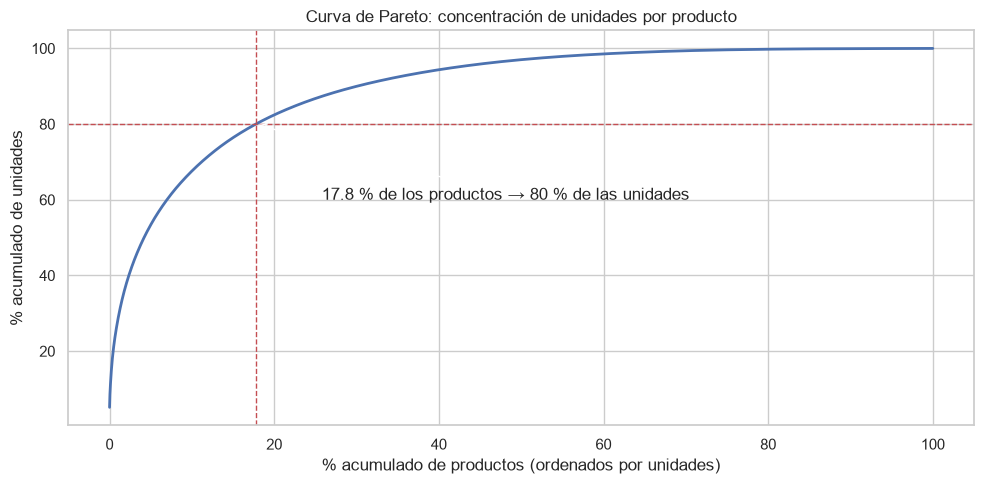

Métrica,Valor
Productos con ventas,"21,807"
Productos que generan el 80 % de las unidades,"3,877"
% de productos que generan el 80 % de las unidades,17.8 %
% de unidades del 1 % de productos más vendidos,28.1 %


item_id,Producto,categoria_principal,Unidades,% de las unidades
20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,Regalos,"187,642",5.14
2808,"Diablo III [PC, Jewel, русская версия]",Videojuegos,"17,245",0.47
3732,"Grand Theft Auto V [PS3, русские субтитры]",Videojuegos,"16,642",0.46
17717,Прием денежных средств для 1С-Онлайн,Otros,"15,830",0.43
5822,Playstation Store пополнение бумажника: Карта оплаты 1000 руб.,Tarjetas de pago,"14,515",0.40


In [25]:
units_by_item = sales.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False)
cumulative_share = units_by_item.cumsum() / units_by_item.sum() * 100
items_for_80 = int((cumulative_share < 80).sum()) + 1
pct_items_for_80 = items_for_80 / len(units_by_item) * 100
pct_items_axis = np.arange(1, len(units_by_item) + 1) / len(units_by_item) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pct_items_axis, cumulative_share.values, linewidth=2)
ax.axhline(80, color="C3", linestyle="--", linewidth=1)
ax.axvline(pct_items_for_80, color="C3", linestyle="--", linewidth=1)
ax.annotate(f"{pct_items_for_80:.1f} % de los productos → 80 % de las unidades",
            xy=(pct_items_for_80, 80), xytext=(pct_items_for_80 + 8, 60),
            arrowprops={"arrowstyle": "->"})
ax.set_title("Curva de Pareto: concentración de unidades por producto")
ax.set_xlabel("% acumulado de productos (ordenados por unidades)")
ax.set_ylabel("% acumulado de unidades")
plt.tight_layout()
plt.show()

top_items = (
    units_by_item.head(5).rename("Unidades").reset_index()
    .merge(items[["item_id", "item_name", "item_category_id"]], on="item_id")
    .merge(sales[["item_id", "categoria_principal"]].drop_duplicates(), on="item_id")
)
top_items["% de las unidades"] = top_items["Unidades"] / units_by_item.sum() * 100

pareto_summary = pd.DataFrame(
    {
        "Métrica": ["Productos con ventas", "Productos que generan el 80 % de las unidades",
                    "% de productos que generan el 80 % de las unidades",
                    "% de unidades del 1 % de productos más vendidos"],
        "Valor": [f"{len(units_by_item):,}", f"{items_for_80:,}", f"{pct_items_for_80:.1f} %",
                  f"{cumulative_share.iloc[int(len(units_by_item) * 0.01) - 1]:.1f} %"],
    }
)
display(style_table(pareto_summary))
style_table(
    top_items.rename(columns={"item_name": "Producto"})
    [["item_id", "Producto", "categoria_principal", "Unidades", "% de las unidades"]],
    {"% de las unidades": "{:.2f}"},
)

**Interpretación**


- Las ventas están muy concentradas: el **17.8 % de los productos (3,877 de 21,807) genera el 80 % de las
  unidades**, y el 1 % más vendido acumula el 28.1 %.
- El producto más vendido no es un artículo de catálogo, sino la bolsa de la tienda (item 20949, "Фирменный
  пакет майка 1С Интерес"), con 187,642 unidades: el 5.14 % de todas las unidades. También aparece en el
  top 5 un concepto de cobro (item 17717, recepción de pagos de 1C-Online).
- Esos artículos no reflejan demanda de producto y distorsionan los totales de unidades. Conviene tenerlos
  identificados en el modelado.

**Unidades por producto en escala logarítmica.** Histograma del total de unidades netas por producto (solo
productos con unidades netas positivas), con contenedores logarítmicos.

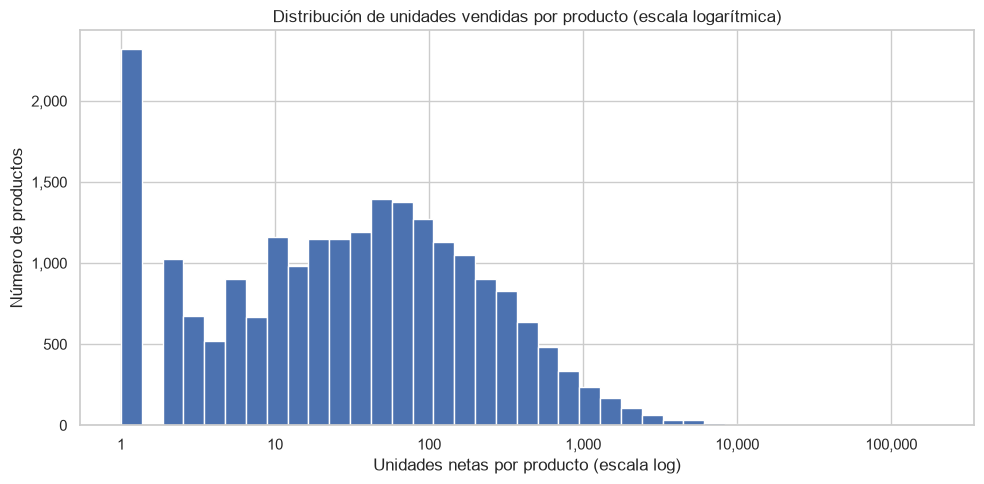

Métrica,Valor
Productos con unidades netas > 0,"21,799"
Productos con unidades netas ≤ 0,8
Mediana de unidades por producto,33
Media de unidades por producto,167.4
Productos con 10 unidades o menos,"6,701 (30.7%)"
"Productos con más de 1,000 unidades",607 (2.8%)


In [26]:
positive_units = units_by_item[units_by_item > 0]
log_bins = np.logspace(0, np.log10(positive_units.max()), 40)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(positive_units, bins=log_bins, edgecolor="white")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Distribución de unidades vendidas por producto (escala logarítmica)")
ax.set_xlabel("Unidades netas por producto (escala log)")
ax.set_ylabel("Número de productos")
plt.tight_layout()
plt.show()

units_distribution = pd.DataFrame(
    {
        "Métrica": ["Productos con unidades netas > 0", "Productos con unidades netas ≤ 0",
                    "Mediana de unidades por producto", "Media de unidades por producto",
                    "Productos con 10 unidades o menos", "Productos con más de 1,000 unidades"],
        "Valor": [f"{len(positive_units):,}", f"{(units_by_item <= 0).sum():,}",
                  f"{positive_units.median():,.0f}", f"{positive_units.mean():,.1f}",
                  f"{(positive_units <= 10).sum():,} ({(positive_units <= 10).mean():.1%})",
                  f"{(positive_units > 1000).sum():,} ({(positive_units > 1000).mean():.1%})"],
    }
)
style_table(units_distribution)

**Interpretación**


- La distribución es de **cola larga**: la mediana es de 33 unidades por producto, pero la media sube a
  167.4 por los productos muy vendidos.
- El 30.7 % de los productos (6,701) vende 10 unidades o menos en todo el periodo, y más de 2,000 productos
  venden una sola unidad (la barra de la izquierda). Solo el 2.8 % (607) supera las 1,000 unidades.
- En escala logarítmica, el grueso de los productos se sitúa entre 10 y 1,000 unidades. Hay 8 productos
  con unidades netas ≤ 0, en los que las devoluciones igualan o superan las ventas.
- Para el pronóstico, esto implica que la mayoría de los pares tienda-producto tendrán ventas mensuales
  muy bajas o nulas.

**Participación por categoría principal.** Porcentaje de las unidades y del revenue que aporta cada
categoría principal, junto con su precio medio por unidad.

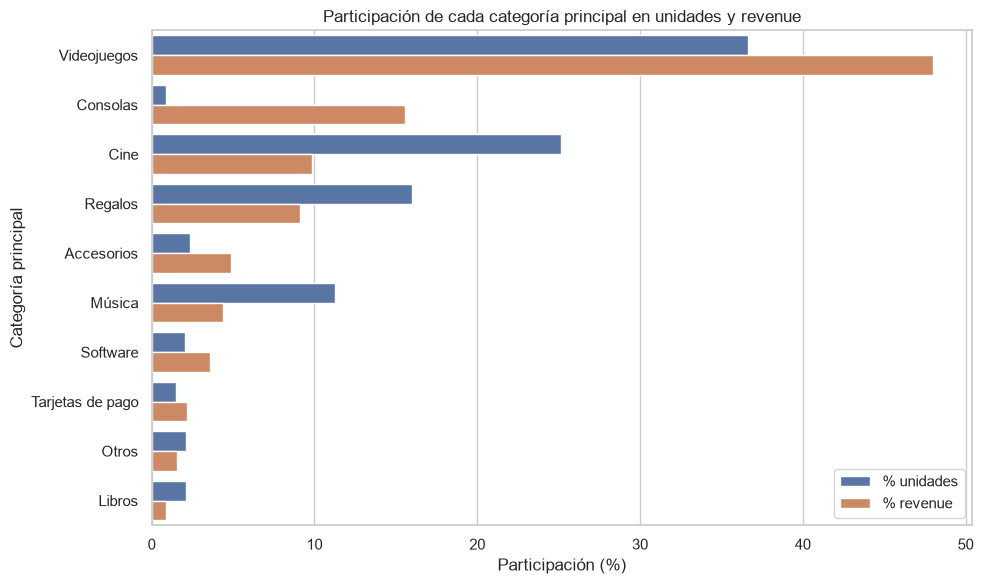

categoria_principal,Unidades,Revenue (M RUB),% unidades,% revenue,Precio medio (RUB)
Videojuegos,"1,335,990","1,631.8",36.6,48.0,"1,221"
Consolas,"32,155",528.0,0.9,15.5,"16,421"
Cine,"916,941",335.0,25.1,9.9,365
Regalos,"584,366",309.1,16.0,9.1,529
Accesorios,"85,059",166.4,2.3,4.9,"1,956"
Música,"411,294",149.7,11.3,4.4,364
Software,"74,954",122.4,2.1,3.6,"1,633"
Tarjetas de pago,"53,883",73.0,1.5,2.1,"1,354"
Otros,"77,217",53.1,2.1,1.6,688
Libros,"76,341",30.3,2.1,0.9,398


In [27]:
category_share = (
    sales.groupby("categoria_principal")
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
    .reset_index()
)
category_share["% unidades"] = category_share["units"] / category_share["units"].sum() * 100
category_share["% revenue"] = category_share["revenue"] / category_share["revenue"].sum() * 100
category_share["Precio medio (RUB)"] = category_share["revenue"] / category_share["units"]
category_share = category_share.sort_values("% revenue", ascending=False)

plot_data = category_share.melt(id_vars="categoria_principal", value_vars=["% unidades", "% revenue"],
                                var_name="Métrica", value_name="Participación (%)")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_data, y="categoria_principal", x="Participación (%)", hue="Métrica", ax=ax)
ax.set_title("Participación de cada categoría principal en unidades y revenue")
ax.set_xlabel("Participación (%)")
ax.set_ylabel("Categoría principal")
ax.legend(title=None)
plt.tight_layout()
plt.show()

style_table(
    category_share.assign(revenue=category_share["revenue"] / 1e6).rename(
        columns={"units": "Unidades", "revenue": "Revenue (M RUB)"}),
    {"Revenue (M RUB)": "{:,.1f}", "% unidades": "{:.1f}", "% revenue": "{:.1f}",
     "Precio medio (RUB)": "{:,.0f}"},
)

**Interpretación**


- **Videojuegos** domina en ambas métricas: 36.6 % de las unidades y 48.0 % del revenue.
- **Consolas** es el caso más desigual: solo el 0.9 % de las unidades, pero el 15.5 % del revenue, por su
  precio medio de 16,421 RUB.
- **Cine** (25.1 % de las unidades), **Regalos** (16.0 %) y **Música** (11.3 %) venden mucho volumen a
  precios bajos (365, 529 y 364 RUB de media), así que pesan bastante menos en revenue (9.9 %, 9.1 % y
  4.4 %).
- Las demás categorías aportan menos del 5 % cada una. *Otros* (envíos, pagos, entradas, pilas) suma el
  2.1 % de las unidades y el 1.6 % del revenue.
- La categoría principal es una variable relevante: el volumen y el precio cambian mucho entre categorías.

#### 5.b.ii Por sucursal

**Distribución por tienda.** Unidades y revenue totales del periodo por tienda. Los totales dependen
también de cuántos meses estuvo activa cada tienda.

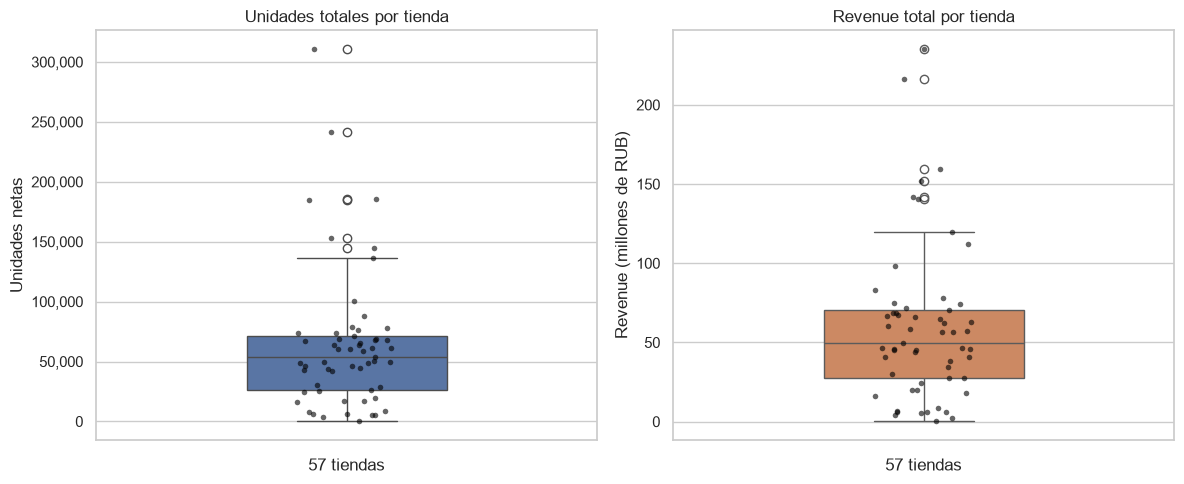

Métrica,Unidades,Revenue (M RUB)
Media,"64,003.5",59.6
Mediana,"53,886.0",49.8
Mínimo,330.0,0.4
Máximo,"310,777.0",235.2
Máximo / mediana,5.8,4.7


shop_id,Tienda,ciudad,Unidades,Revenue (M RUB),% revenue,Meses activos
31,"Москва ТЦ ""Семеновский""",Moskva,"310,777",235.2,6.92,34
25,"Москва ТРК ""Атриум""",Moskva,"241,919",216.5,6.37,34
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",Moskva,"184,557",159.7,4.70,34
42,"СПб ТК ""Невский Центр""",Sankt-Peterburg,"144,933",151.9,4.47,34
54,"Химки ТЦ ""Мега""",Khimki,"185,789",141.9,4.18,28
32,"Москва ТЦ ""Серебряный Дом""",Moskva,"8,781",5.8,0.17,7
23,"Москва ТК ""Буденовский"" (пав.А2)",Moskva,"7,705",5.6,0.17,4
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",Rostov-na-Donu,"4,943",4.3,0.13,11
8,"Воронеж ТРЦ Сити-Парк ""Град""",Voronezh,"3,595",2.3,0.07,4
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",Novosibirsk,330,0.4,0.01,1


In [28]:
shop_totals = (
    sales.groupby(["shop_id", "ciudad", "tipo_tienda"])
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"),
         active_months=("date_block_num", "nunique"))
    .reset_index()
)
shop_totals["revenue_m"] = shop_totals["revenue"] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=shop_totals["units"], ax=axes[0], color="C0", width=0.4)
sns.stripplot(y=shop_totals["units"], ax=axes[0], color="black", size=4, alpha=0.6)
axes[0].set_title("Unidades totales por tienda")
axes[0].set_ylabel("Unidades netas")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
sns.boxplot(y=shop_totals["revenue_m"], ax=axes[1], color="C1", width=0.4)
sns.stripplot(y=shop_totals["revenue_m"], ax=axes[1], color="black", size=4, alpha=0.6)
axes[1].set_title("Revenue total por tienda")
axes[1].set_ylabel("Revenue (millones de RUB)")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for ax in axes:
    ax.set_xlabel(f"{len(shop_totals)} tiendas")
plt.tight_layout()
plt.show()

shop_stats = pd.DataFrame(
    {
        "Métrica": ["Media", "Mediana", "Mínimo", "Máximo", "Máximo / mediana"],
        "Unidades": [shop_totals["units"].mean(), shop_totals["units"].median(),
                     shop_totals["units"].min(), shop_totals["units"].max(),
                     shop_totals["units"].max() / shop_totals["units"].median()],
        "Revenue (M RUB)": [shop_totals["revenue_m"].mean(), shop_totals["revenue_m"].median(),
                            shop_totals["revenue_m"].min(), shop_totals["revenue_m"].max(),
                            shop_totals["revenue_m"].max() / shop_totals["revenue_m"].median()],
    }
)
display(style_table(shop_stats, {"Unidades": "{:,.1f}", "Revenue (M RUB)": "{:,.1f}"}))

shop_ranking = shop_totals.sort_values("revenue", ascending=False)
shop_ranking["% revenue"] = shop_ranking["revenue"] / shop_ranking["revenue"].sum() * 100
shop_ranking = shop_ranking.merge(shops, on="shop_id")
style_table(
    pd.concat([shop_ranking.head(5), shop_ranking.tail(5)])
    .rename(columns={"shop_name": "Tienda", "units": "Unidades", "revenue_m": "Revenue (M RUB)",
                     "active_months": "Meses activos"})
    [["shop_id", "Tienda", "ciudad", "Unidades", "Revenue (M RUB)", "% revenue", "Meses activos"]],
    {"Revenue (M RUB)": "{:,.1f}", "% revenue": "{:.2f}"},
)

**Interpretación**


- Las tiendas son muy heterogéneas: la mediana es de 53,886 unidades y 49.8 M RUB, pero la mayor, la
  tienda 31 (Moskva, ТЦ "Семеновский"), vende 310,777 unidades y 235.2 M RUB, unas 5.8 veces la mediana en
  unidades.
- Las 5 tiendas con más revenue (31, 25, 28, 42 y 54) reúnen el 26.6 % del revenue total. Cuatro están en
  Moscú o su entorno, y la otra en San Petersburgo.
- Los totales más bajos corresponden a tiendas con pocos meses activos: la 36 (Novosibirsk) solo tiene
  1 mes de ventas y la 8 (Voronezh) y la 23 (Moskva), 4. Su bajo total refleja actividad parcial, no
  necesariamente bajo rendimiento.
- El boxplot muestra varias tiendas atípicas por arriba en ambas métricas. La tienda es una variable clave
  y conviene comparar tiendas por mes activo y no solo por totales.

**Participación por ciudad.** Porcentaje de las unidades y del revenue por ciudad, ordenado por revenue.

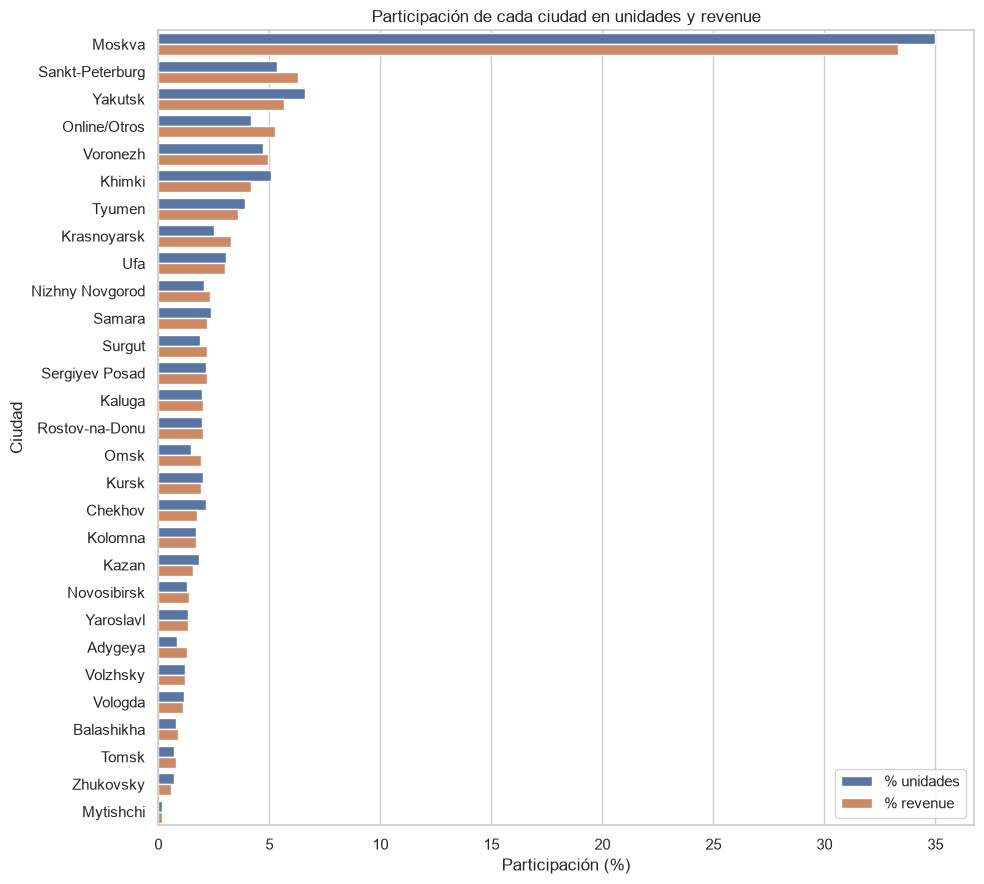

Ciudad,Tiendas,Unidades,% unidades,Revenue (M RUB),% revenue
Moskva,13,"1,276,374",35.0,"1,132.7",33.3
Sankt-Peterburg,2,"195,541",5.4,214.1,6.3
Yakutsk,2,"240,857",6.6,191.6,5.6
Online/Otros,3,"152,732",4.2,178.4,5.2
Voronezh,3,"171,142",4.7,167.4,4.9
Khimki,1,"185,789",5.1,141.9,4.2
Tyumen,3,"142,093",3.9,122.3,3.6
Krasnoyarsk,2,"91,324",2.5,111.2,3.3
Ufa,2,"111,401",3.1,101.6,3.0
Nizhny Novgorod,2,"75,467",2.1,78.8,2.3


In [29]:
city_share = (
    sales.groupby("ciudad")
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), n_shops=("shop_id", "nunique"))
    .reset_index()
)
city_share["% unidades"] = city_share["units"] / city_share["units"].sum() * 100
city_share["% revenue"] = city_share["revenue"] / city_share["revenue"].sum() * 100
city_share = city_share.sort_values("% revenue", ascending=False)

plot_data = city_share.melt(id_vars="ciudad", value_vars=["% unidades", "% revenue"],
                            var_name="Métrica", value_name="Participación (%)")
fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(data=plot_data, y="ciudad", x="Participación (%)", hue="Métrica", ax=ax)
ax.set_title("Participación de cada ciudad en unidades y revenue")
ax.set_xlabel("Participación (%)")
ax.set_ylabel("Ciudad")
ax.legend(title=None)
plt.tight_layout()
plt.show()

style_table(
    city_share.head(10).assign(revenue=lambda d: d["revenue"] / 1e6).rename(
        columns={"ciudad": "Ciudad", "n_shops": "Tiendas", "units": "Unidades",
                 "revenue": "Revenue (M RUB)"})
    [["Ciudad", "Tiendas", "Unidades", "% unidades", "Revenue (M RUB)", "% revenue"]],
    {"% unidades": "{:.1f}", "% revenue": "{:.1f}", "Revenue (M RUB)": "{:,.1f}"},
)

**Interpretación**


- **Moskva** concentra el 35.0 % de las unidades y el 33.3 % del revenue con 13 tiendas, más de cinco
  veces cualquier otra ciudad.
- Le siguen Sankt-Peterburg (6.3 % del revenue), Yakutsk (5.6 %), el canal Online/Otros (5.2 %), Voronezh
  (4.9 %) y Khimki (4.2 %). Las demás ciudades aportan menos del 4 % cada una.
- Algunas ciudades tienen más peso en revenue que en unidades, como Sankt-Peterburg (6.3 % frente a 5.4 %)
  y Online/Otros (5.2 % frente a 4.2 %), lo que sugiere una mezcla de productos más cara. En Yakutsk ocurre
  lo contrario (6.6 % de las unidades y 5.6 % del revenue).

#### 5.b.iii Por periodo

**Totales por año.** El histórico termina en octubre de 2015, así que 2015 solo tiene 10 meses. Para
comparar años en igualdad de condiciones se calculan también los totales de enero a octubre de cada año.

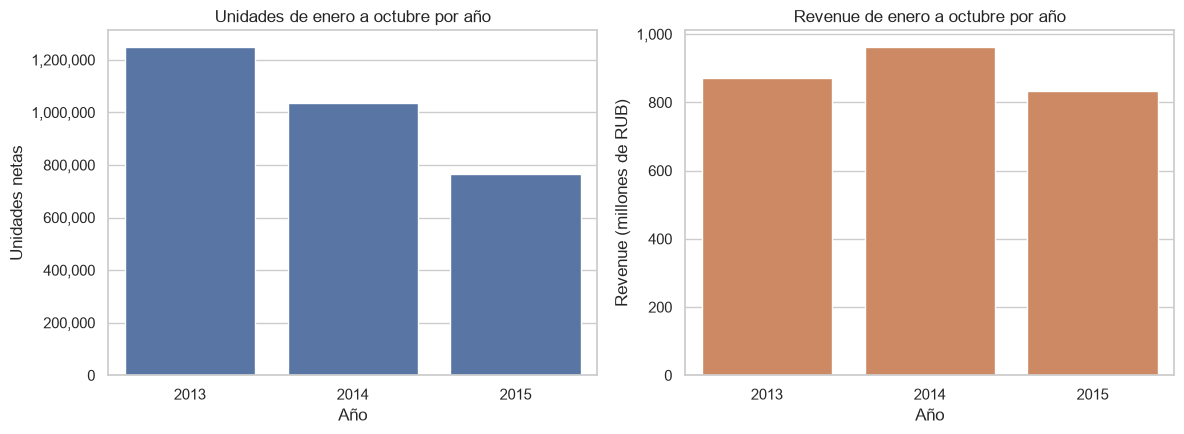

Año,Meses,Unidades,Revenue (M RUB),Unidades ene–oct,Revenue ene–oct (M RUB),Var. unidades ene–oct (%),Var. revenue ene–oct (%)
2013,12,"1,562,732","1,217.5","1,249,381",871.3,—,—
2014,12,"1,320,884","1,346.8","1,034,285",962.7,-17.2,+10.5
2015,10,"764,584",834.6,"764,584",834.6,-26.1,-13.3


In [30]:
sales["year"] = sales["date"].dt.year
sales["month"] = sales["date"].dt.month
is_jan_oct = sales["month"] <= 10

yearly = sales.groupby("year").agg(months=("month", "nunique"), units=("item_cnt_day", "sum"),
                                   revenue=("revenue", "sum"))
yearly_jan_oct = sales[is_jan_oct].groupby("year").agg(units_jan_oct=("item_cnt_day", "sum"),
                                                       revenue_jan_oct=("revenue", "sum"))
yearly = yearly.join(yearly_jan_oct).reset_index()
yearly["Var. unidades ene–oct (%)"] = yearly["units_jan_oct"].pct_change() * 100
yearly["Var. revenue ene–oct (%)"] = yearly["revenue_jan_oct"].pct_change() * 100
for col in ["revenue", "revenue_jan_oct"]:
    yearly[col] = yearly[col] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=yearly, x="year", y="units_jan_oct", ax=axes[0], color="C0")
axes[0].set_title("Unidades de enero a octubre por año")
axes[0].set_ylabel("Unidades netas")
sns.barplot(data=yearly, x="year", y="revenue_jan_oct", ax=axes[1], color="C1")
axes[1].set_title("Revenue de enero a octubre por año")
axes[1].set_ylabel("Revenue (millones de RUB)")
for ax in axes:
    ax.set_xlabel("Año")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

style_table(
    yearly.rename(columns={"year": "Año", "months": "Meses", "units": "Unidades",
                           "revenue": "Revenue (M RUB)", "units_jan_oct": "Unidades ene–oct",
                           "revenue_jan_oct": "Revenue ene–oct (M RUB)"}),
    {"Año": "{}", "Revenue (M RUB)": "{:,.1f}", "Revenue ene–oct (M RUB)": "{:,.1f}",
     "Var. unidades ene–oct (%)": "{:+.1f}", "Var. revenue ene–oct (%)": "{:+.1f}"},
)

**Interpretación**


- Comparando enero–octubre, las **unidades caen de forma sostenida**: −17.2 % en 2014 y −26.1 % en 2015,
  hasta 764,584 unidades.
- El **revenue no cae al mismo ritmo**: sube un 10.5 % en 2014 (de 871.3 a 962.7 M RUB) y baja un 13.3 % en
  2015 (834.6 M RUB). Se venden menos unidades, pero más caras. Los valores están en rublos nominales,
  por lo que incluyen el efecto de la inflación y de la devaluación del rublo de finales de 2014.
- Los totales anuales sin ajustar exageran la caída de 2015 (764,584 unidades frente a 1,320,884 en 2014),
  porque 2015 no incluye noviembre ni diciembre, los meses más fuertes.

**Por mes del año.** Unidades y revenue de cada mes calendario, con una línea por año.

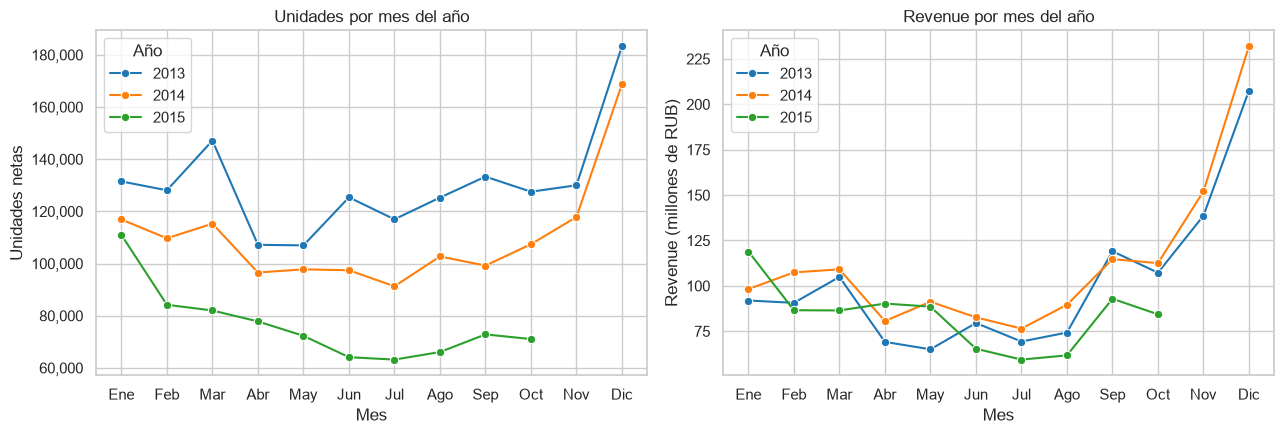

Mes,2013,2014,2015,Media mensual
Ene,"131,478","116,899","110,971","119,783"
Feb,"128,090","109,686","84,198","107,325"
Mar,"147,142","115,296","82,014","114,817"
Abr,"107,190","96,556","77,827","93,858"
May,"106,970","97,789","72,295","92,351"
Jun,"125,381","97,429","64,114","95,641"
Jul,"116,966","91,279","63,187","90,477"
Ago,"125,291","102,721","66,079","98,030"
Sep,"133,332","99,208","72,843","101,794"
Oct,"127,541","107,422","71,056","102,006"


In [31]:
MONTH_NAMES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

monthly = sales.groupby(["year", "month"]).agg(units=("item_cnt_day", "sum"),
                                               revenue=("revenue", "sum")).reset_index()
monthly["revenue_m"] = monthly["revenue"] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for metric, ax, title, ylabel in [
    ("units", axes[0], "Unidades por mes del año", "Unidades netas"),
    ("revenue_m", axes[1], "Revenue por mes del año", "Revenue (millones de RUB)"),
]:
    sns.lineplot(data=monthly, x="month", y=metric, hue="year", marker="o", palette="tab10", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Mes")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 13), MONTH_NAMES)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(title="Año")
plt.tight_layout()
plt.show()

monthly_table = monthly.pivot(index="month", columns="year", values="units")
monthly_table.index = MONTH_NAMES
monthly_table["Media mensual"] = monthly_table.mean(axis=1)
monthly_table = monthly_table.reset_index(names="Mes")
monthly_table.columns = monthly_table.columns.astype(str)
style_table(monthly_table, {c: "{:,.0f}" for c in monthly_table.columns[1:]})

**Interpretación**


- **Diciembre es el pico claro** del año: 183,342 unidades en 2013 y 168,754 en 2014, frente a una media
  mensual de entre 90,000 y 124,000 en el resto de meses. En revenue el pico es todavía más pronunciado.
- **Noviembre sube respecto a octubre** en los dos años con datos: +1.9 % en unidades en 2013 (de 127,541 a
  130,009) y +9.7 % en 2014 (de 107,422 a 117,845). En revenue el salto es mayor. Es una referencia directa
  para el pronóstico de noviembre de 2015, cuyo octubre fue de 71,056 unidades.
- El verano (junio–agosto) es la temporada baja, y hay picos en enero, marzo y septiembre.
- 2015 está por debajo de los años anteriores en casi todos los meses en unidades, aunque en revenue se
  mantiene cerca de 2013 y 2014 hasta mayo.

**Por semana del año.** Unidades y revenue por semana ISO, con una línea por año ISO. La primera y la
última semana del histórico pueden estar incompletas.

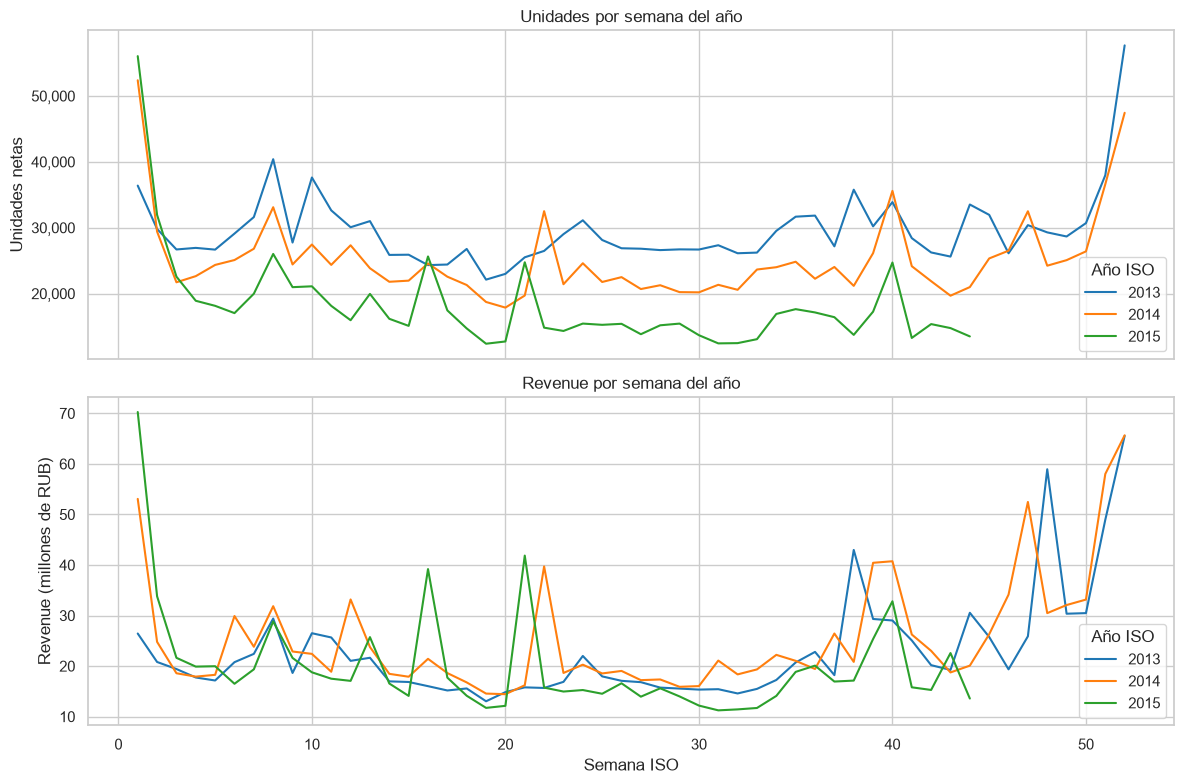

Métrica,Valor
Semanas completas,146
Mediana de unidades por semana,"24,500"
Semana 52 de 2013,"57,680 unidades"
Semana 1 de 2015,"56,048 unidades"
Semana 1 de 2014,"52,385 unidades"
Semana 52 de 2014,"47,444 unidades"
Semana 8 de 2013,"40,401 unidades"


In [32]:
iso = sales["date"].dt.isocalendar()
weekly = (
    sales.assign(iso_year=iso["year"].astype(int), iso_week=iso["week"].astype(int))
    .groupby(["iso_year", "iso_week"])
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), days=("date", "nunique"))
    .reset_index()
)
weekly["revenue_m"] = weekly["revenue"] / 1e6

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for metric, ax, title, ylabel in [
    ("units", axes[0], "Unidades por semana del año", "Unidades netas"),
    ("revenue_m", axes[1], "Revenue por semana del año", "Revenue (millones de RUB)"),
]:
    sns.lineplot(data=weekly, x="iso_week", y=metric, hue="iso_year", palette="tab10", ax=ax)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(title="Año ISO")
axes[1].set_xlabel("Semana ISO")
plt.tight_layout()
plt.show()

full_weeks = weekly[weekly["days"] == 7]
top_weeks = full_weeks.nlargest(5, "units")
style_table(
    pd.DataFrame(
        {
            "Métrica": ["Semanas completas", "Mediana de unidades por semana",
                        *[f"Semana {w} de {y}" for y, w in zip(top_weeks["iso_year"],
                                                                top_weeks["iso_week"])]],
            "Valor": [f"{len(full_weeks)}", f"{full_weeks['units'].median():,.0f}",
                      *[f"{u:,} unidades" for u in top_weeks["units"]]],
        }
    )
)

**Interpretación**


- La mediana es de 24,500 unidades por semana completa (146 semanas).
- Las semanas más fuertes coinciden con el fin de año: la semana 52 de 2013 (57,680 unidades) y la semana 1
  de 2015 (56,048), que en el calendario ISO va del 29/12/2014 al 04/01/2015. Les siguen la semana 1 de 2014
  y la 52 de 2014.
- Fuera de diciembre destaca la semana 8 de 2013 (40,401 unidades, del 18 al 24 de febrero), que coincide
  con la festividad del 23 de febrero en Rusia, una fecha de regalos.
- En revenue aparecen picos aislados sin un aumento equivalente de unidades. El más claro es la semana 48
  de 2013, con casi el doble de revenue que las semanas vecinas y unidades en niveles normales. Son
  compatibles con lanzamientos de productos caros, como videojuegos o consolas, y conviene verificarlos en
  el análisis por producto.

**Por día de la semana.** Media diaria de unidades y revenue según el día de la semana.

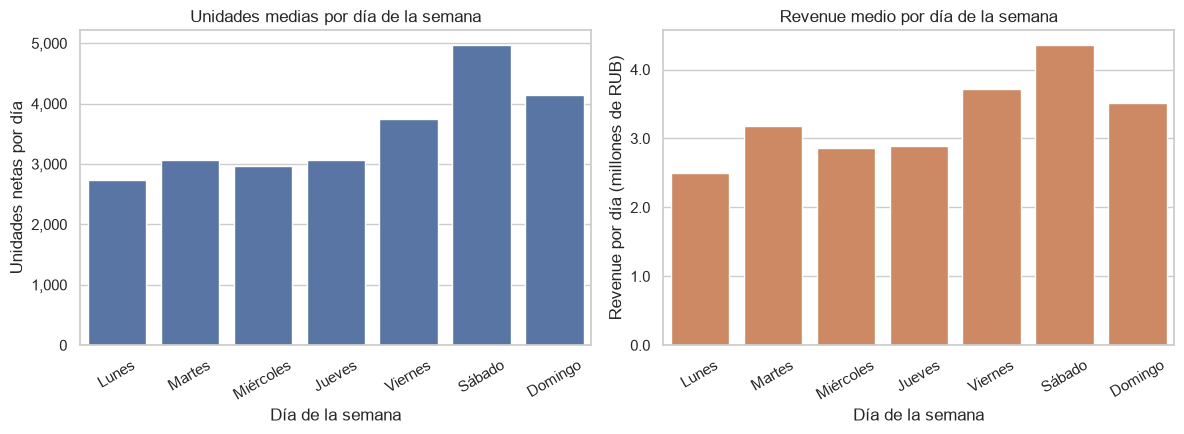

Día,Días,Unidades medias,Revenue medio (M RUB),Índice vs. media (%)
Lunes,147,"2,731",2.49,77
Martes,148,"3,074",3.17,87
Miércoles,148,"2,971",2.87,84
Jueves,148,"3,072",2.89,87
Viernes,148,"3,740",3.72,106
Sábado,148,"4,964",4.35,141
Domingo,147,"4,145",3.51,117


In [33]:
daily = sales.groupby("date").agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
daily["weekday"] = daily.index.day_of_week
by_weekday = daily.groupby("weekday").agg(units=("units", "mean"), revenue=("revenue", "mean"),
                                          days=("units", "size"))
by_weekday["revenue_m"] = by_weekday["revenue"] / 1e6
by_weekday["day"] = [DAY_NAMES[d] for d in by_weekday.index]
by_weekday["Índice vs. media (%)"] = by_weekday["units"] / daily["units"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=by_weekday, x="day", y="units", ax=axes[0], color="C0")
axes[0].set_title("Unidades medias por día de la semana")
axes[0].set_ylabel("Unidades netas por día")
sns.barplot(data=by_weekday, x="day", y="revenue_m", ax=axes[1], color="C1")
axes[1].set_title("Revenue medio por día de la semana")
axes[1].set_ylabel("Revenue por día (millones de RUB)")
for ax in axes:
    ax.set_xlabel("Día de la semana")
    ax.tick_params(axis="x", rotation=30)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.1f}" if ax is axes[1] else "{x:,.0f}"))
plt.tight_layout()
plt.show()

style_table(
    by_weekday.rename(columns={"day": "Día", "days": "Días", "units": "Unidades medias",
                               "revenue_m": "Revenue medio (M RUB)"})
    [["Día", "Días", "Unidades medias", "Revenue medio (M RUB)", "Índice vs. media (%)"]],
    {"Unidades medias": "{:,.0f}", "Revenue medio (M RUB)": "{:,.2f}", "Índice vs. media (%)": "{:.0f}"},
)

**Interpretación**


- El **sábado** es el día más fuerte: 4,964 unidades y 4.35 M RUB de media, un 41 % por encima de la media
  diaria. Le siguen el domingo (4,145 unidades) y el viernes (3,740).
- El **lunes** es el día más débil: 2,731 unidades y 2.49 M RUB, un 23 % por debajo de la media. De martes a
  jueves los valores son parecidos (entre 2,971 y 3,074 unidades).
- El ciclo semanal es marcado, pero cada mes contiene un número similar de cada día de la semana, así que
  su efecto se compensa casi por completo al agregar por mes.

#### Guardado de los datos enriquecidos

Se guardan `sales_clean` y las columnas nuevas (`revenue`, `item_category_id`, `categoria_principal`,
`ciudad` y `tipo_tienda`) en `data/interim/sales_enriched.parquet`. Las columnas de texto repetitivas se
almacenan como `category` para reducir tamaño; los nombres originales en ruso pueden recuperarse uniendo
con los catálogos.

In [34]:
ENRICHED_COLUMNS = ["date", "date_block_num", "shop_id", "item_id", "item_price", "item_cnt_day",
                    "revenue", "item_category_id", "categoria_principal", "ciudad", "tipo_tienda"]

sales_enriched = sales[ENRICHED_COLUMNS].copy()
for col in ["categoria_principal", "ciudad", "tipo_tienda"]:
    sales_enriched[col] = sales_enriched[col].astype("category")

enriched_path = INTERIM_PATH / ENRICHED_SALES_FILE
sales_enriched.to_parquet(enriched_path, index=False)
reloaded = load_parquet(ENRICHED_SALES_FILE)

style_table(
    pd.DataFrame(
        {
            "Verificación": ["Archivo", "Registros", "Columnas", "Memoria en pandas (MB)",
                             "Filas y tipos al releer"],
            "Resultado": [enriched_path.as_posix(), f"{len(sales_enriched):,}",
                          f"{sales_enriched.shape[1]}", f"{memory_mb(sales_enriched):,.2f}",
                          "Coinciden" if reloaded.shape == sales_enriched.shape
                          and reloaded.dtypes.equals(sales_enriched.dtypes) else "No coinciden"],
        }
    )
)

Verificación,Resultado
Archivo,../data/interim/sales_enriched.parquet
Registros,"2,935,843"
Columnas,11
Memoria en pandas (MB),100.79
Filas y tipos al releer,Coinciden
